# Data cleaning

In [ ]:
import pandas as pd
import re

In [5]:
df = pd.read_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/all_results.csv')

In [10]:
print(df.columns.tolist())

['id', 'time_window_start', 'tweets_struct', 'name', 'username', 'description', 'location', 'public_metrics.followers_count', 'profile_image_url', 'clean...pool', 'is_empty_window', 'window_weeks_to_election', 'profile_image_description', 'profile_image_main_info', 'Model', 'Belief_Raw', 'Belief_Cleaned', 'Demo_Raw', 'Demo_Cleaned', 'Belief_opinion_on_the_number_of_immigrants_in_america_Category', 'Belief_opinion_on_the_number_of_immigrants_in_america_Explanation', 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol', 'Belief_opinion_on_the_number_of_immigrants_in_america_Speculation', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Category', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Explanation', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Speculation', 'Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_t

In [6]:
df = df[['id', 'time_window_start', 'username', 'Demo_sex_Symbol', 'Demo_age_Symbol', 'Demo_ethnicity_Symbol', 'Demo_highest_educational_qualification_Symbol','Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol', 'Demo_interest_in_politics_Symbol', 'Demo_marital_status_Symbol', 'Demo_partisan_loyalties_Symbol','Demo_which_state_of_the_usa_do_they_live_in__Category','Demo_household_income_bracket_Symbol','Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol']]

In [8]:
df_filtered = df.dropna()

In [ ]:
#unify the symbol output format

def clean_column_pattern(value):
    if pd.isna(value):
        return value
    
    value_str = str(value)
    
    # Pattern: 1+ letters, 1+ digits, optional parenthesis
    match = re.search(r'([a-zA-Z]+\d+)\)?', value_str)
    if match:
        return match.group(1)
    
    return value  # or np.nan if you want to remove non-matches

# Apply to all symbol columns
columns_to_clean = ['Demo_sex_Symbol', 'Demo_age_Symbol', 'Demo_ethnicity_Symbol', 'Demo_highest_educational_qualification_Symbol','Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol', 'Demo_interest_in_politics_Symbol', 'Demo_marital_status_Symbol', 'Demo_partisan_loyalties_Symbol','Demo_household_income_bracket_Symbol','Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol']
df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)


/tmp/ipykernel_2679/1055479848.py:21: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)
/tmp/ipykernel_2679/1055479848.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)


In [16]:
df_filtered

,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_interest_in_politics_Symbol,Demo_marital_status_Symbol,Demo_partisan_loyalties_Symbol,Demo_which_state_of_the_usa_do_they_live_in__Category,Demo_household_income_bracket_Symbol,Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol,state_cleaned
40,1542629834953719810,2024-05-19 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
41,1542629834953719810,2024-06-16 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
43,1542629834953719810,2024-07-14 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
44,1542629834953719810,2024-07-28 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa3,i4,m2,pid3,ohio,h2,sob1,OH
45,1542629834953719810,2024-08-11 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i4,m2,pid3,illinois,h3,sob1,IL
23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,m2,pid3,illinois,h4,sob1,IL
23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,m2,pid4,illinois,h3,sob1,IL
23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa1,i3,m2,pid4,illinois,h3,sob1,IL


In [20]:
df_filtered.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/new_abortion_result.csv')

In [21]:
df_filtered = pd.read_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/new_abortion_result.csv')

In [17]:
df_filtered['Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol'].unique()

array(['sob4', 'sob1', 'sob2', 'sob3'], dtype=object)

In [ ]:
# clean up state variable
state_abbreviation_mapping = {
    'alabama': 'AL',
    'alaska': 'AK',
    'arizona': 'AZ',
    'arkansas': 'AR',
    'california': 'CA',
    'colorado': 'CO',
    'connecticut': 'CT',
    'delaware': 'DE',
    'florida': 'FL',
    'georgia': 'GA',
    'hawaii': 'HI',
    'idaho': 'ID',
    'illinois': 'IL',
    'indiana': 'IN',
    'iowa': 'IA',
    'kansas': 'KS',
    'kentucky': 'KY',
    'louisiana': 'LA',
    'maine': 'ME',
    'maryland': 'MD',
    'massachusetts': 'MA',
    'michigan': 'MI',
    'minnesota': 'MN',
    'mississippi': 'MS',
    'missouri': 'MO',
    'montana': 'MT',
    'nebraska': 'NE',
    'nevada': 'NV',
    'new hampshire': 'NH',
    'new jersey': 'NJ',
    'new mexico': 'NM',
    'new york': 'NY',
    'north carolina': 'NC',
    'north dakota': 'ND',
    'ohio': 'OH',
    'oklahoma': 'OK',
    'oregon': 'OR',
    'pennsylvania': 'PA',
    'rhode island': 'RI',
    'south carolina': 'SC',
    'south dakota': 'SD',
    'tennessee': 'TN',
    'texas': 'TX',
    'utah': 'UT',
    'vermont': 'VT',
    'virginia': 'VA',
    'washington': 'WA',
    'west virginia': 'WV',
    'wisconsin': 'WI',
    'wyoming': 'WY',
    # Handle the "not specified" cases
    'usa (not a specific state)': 'No State',
    'usa (no specific state identified)': 'No State',
    'usa (the user is from the united states but does not specify a state)': 'No State',
    'usa (the user is from the united states but no specific state is identified)': 'No State',
    'if they do not specify a state, but are still from the united states of america, write "usa"': 'No State',
    'not from a state in the usa': 'No State',
    'not from a state in the usa,': 'No State',
}
df_filtered['state_cleaned'] = df_filtered['Demo_which_state_of_the_usa_do_they_live_in__Category'].apply(lambda x: state_abbreviation_mapping.get(x.strip().lower(), x.strip().capitalize()))
print(df_filtered['state_cleaned'].value_counts(dropna=False))


state_cleaned
Usa             1736
CA              1025
NY               731
FL               585
TX               573
                ... 
Connecticut,       1
Michigan,          1
Ny,                1
Tennessee,         1
Utah,              1
Name: count, Length: 119, dtype: int64


/tmp/ipykernel_2679/2325943952.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['state_cleaned'] = df_filtered['Demo_which_state_of_the_usa_do_they_live_in__Category'].apply(lambda x: state_abbreviation_mapping.get(x.strip().lower(), x.strip().capitalize()))


In [ ]:
# further clean up for state variables
STATE_MAPPING = {
    # Standard abbreviations
    'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR', 'california': 'CA',
    'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE', 'florida': 'FL', 'georgia': 'GA',
    'hawaii': 'HI', 'idaho': 'ID', 'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA',
    'kansas': 'KS', 'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
    'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS', 'missouri': 'MO',
    'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV', 'new hampshire': 'NH', 'new jersey': 'NJ',
    'new mexico': 'NM', 'new york': 'NY', 'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH',
    'oklahoma': 'OK', 'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
    'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT', 'vermont': 'VT',
    'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV', 'wisconsin': 'WI', 'wyoming': 'WY',
    'district of columbia': 'DC', 'washington dc': 'DC', 'dc': 'DC',
    'ny,':'NY',  'wa,': 'WA',
    # Handle common variations
    'california,': 'CA', 'new york,': 'NY', 'texas,': 'TX', 'florida,': 'FL', 'illinois,': 'IL',
    'massachusetts,': 'MA', 'michigan,': 'MI', 'minnesota,': 'MN', 'arizona,': 'AZ', 'nevada,': 'NV',
    'tennessee,': 'TN', 'south carolina,': 'SC', 'kansas,': 'KS', 'louisiana,': 'LA', 'maine,': 'ME',
    'connecticut,': 'CT', 'utah,': 'UT', 'idaho,': 'NV',
    
    # Handle parenthetical variations
    'california (ca)': 'CA', 'arizona (az)': 'AZ', 'kansas (ks)': 'KS', 'tennessee (tn)': 'TN',
    'hi (hawaii)': 'HI', 'ma (massachusetts)': 'MA', 'ca (california)': 'CA',
    
    # Handle USA cases
    'usa': 'USA', 'usa,': 'USA', 'usa (no specific state)': 'USA', 'usa (unspecified state)': 'USA',
    'if they do not specify a state, but are still from the united states of america, write "usa"': 'USA',
    'no state': 'USA'
}

def clean_state(state):
    if pd.isna(state):
        return 'USA'
    
    state_str = str(state).strip().lower()
    
    # Direct mapping lookup
    if state_str in STATE_MAPPING:
        return STATE_MAPPING[state_str]
    
    # Handle case variations
    if len(state_str) == 2 and state_str.upper() in STATE_MAPPING.values():
        return state_str.upper()
    
    # Handle common prefixes
    if state_str.startswith('new '):
        state_str = 'new ' + state_str[4:]
    elif state_str.startswith('north '):
        state_str = 'north ' + state_str[6:]
    elif state_str.startswith('south '):
        state_str = 'south ' + state_str[6:]
    elif state_str.startswith('west '):
        state_str = 'west ' + state_str[5:]
    
    # Try to find partial matches
    for key, value in STATE_MAPPING.items():
        if key in state_str:
            return value
    
    # If no match found, return original in uppercase
    return state_str.upper()

df_filtered['state_cleaned'] = df_filtered['state_cleaned'].apply(clean_state)

print(len(df_filtered['state_cleaned'].value_counts()))

49


/tmp/ipykernel_2679/1557629176.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['state_cleaned'] = df_filtered['state_cleaned'].apply(clean_state)


In [14]:
print(len(df_filtered['state_cleaned'].value_counts()))

48


In [13]:
df_filtered = df_filtered[df_filtered['state_cleaned'] != 'USA']

In [19]:
df_filtered

,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_interest_in_politics_Symbol,Demo_marital_status_Symbol,Demo_partisan_loyalties_Symbol,Demo_which_state_of_the_usa_do_they_live_in__Category,Demo_household_income_bracket_Symbol,Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol,state_cleaned
40,1542629834953719810,2024-05-19 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
41,1542629834953719810,2024-06-16 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
43,1542629834953719810,2024-07-14 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
44,1542629834953719810,2024-07-28 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa3,i4,m2,pid3,ohio,h2,sob1,OH
45,1542629834953719810,2024-08-11 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i4,m2,pid3,illinois,h3,sob1,IL
23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,m2,pid3,illinois,h4,sob1,IL
23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,m2,pid4,illinois,h3,sob1,IL
23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa1,i3,m2,pid4,illinois,h3,sob1,IL


1. None center parametrization
2. change ICAR with pre existing methods and seperate islands
3. incorporate hard sum to zero for all categories (for ICAR try and see whether it works)

/tmp/ipykernel_33223/3953011180.py:38: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = weights.Queen.from_dataframe(shp)
/home/yuyue/stan_env/lib/python3.12/site-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 23.
  W.__init__(self, neighbors, ids=ids, **kw)
21:34:20 - cmdstanpy - INFO - compiling stan file /home/yuyue/stan_projects/mrp.stan to exe file /home/yuyue/stan_projects/mrp
21:34:31 - cmdstanpy - INFO - compiled model executable: /home/yuyue/stan_projects/mrp
21:34:31 - cmdstanpy - INFO - Chain [1] start processing
21:34:31 - cmdstanpy - INFO - Chain [2] start processing
21:34:31 - cmdstanpy - INFO - Chain [3] start processing
21:34:31 - cmdstanpy - INFO - Chain [4] start processing
21:34:31 - cmdstanpy - INFO - Chain [5] start processing
21:34:31 

Chain [1] method = sample (Default)
Chain [1] sample
Chain [1] num_samples = 1000 (Default)
Chain [1] num_warmup = 2000
Chain [1] save_warmup = false (Default)
Chain [1] thin = 1 (Default)
Chain [1] adapt
Chain [1] engaged = true (Default)
Chain [1] gamma = 0.05 (Default)
Chain [1] delta = 0.995
Chain [1] kappa = 0.75 (Default)
Chain [1] t0 = 10 (Default)
Chain [1] init_buffer = 75 (Default)
Chain [1] term_buffer = 50 (Default)
Chain [1] window = 25 (Default)
Chain [1] save_metric = false (Default)
Chain [1] algorithm = hmc (Default)
Chain [1] hmc
Chain [1] engine = nuts (Default)
Chain [1] nuts
Chain [1] max_depth = 13
Chain [1] metric = diag_e (Default)
Chain [1] metric_file =  (Default)
Chain [1] stepsize = 1 (Default)
Chain [1] stepsize_jitter = 0 (Default)
Chain [1] num_chains = 1 (Default)
Chain [1] id = 1 (Default)
Chain [1] data
Chain [1] file = /tmp/tmp2k2_ivxq/450yduhf.json
Chain [1] init = 2 (Default)
Chain [1] random
Chain [1] seed = 14156
Chain [1] output
Chain [1] file = 

12:47:07 - cmdstanpy - INFO - Chain [5] done processing


Chain [5] 
Chain [5] Elapsed Time: 37322.7 seconds (Warm-up)
Chain [5] 19442.3 seconds (Sampling)
Chain [5] 56765 seconds (Total)
Chain [5] 
Chain [5] 
Chain [4] Iteration: 3000 / 3000 [100%]  (Sampling)


12:48:07 - cmdstanpy - INFO - Chain [4] done processing


Chain [4] 
Chain [4] Elapsed Time: 37511 seconds (Warm-up)
Chain [4] 19315.9 seconds (Sampling)
Chain [4] 56827 seconds (Total)
Chain [4] 
Chain [4] 
Chain [1] Iteration: 3000 / 3000 [100%]  (Sampling)


... (10 outputs left out)

12:56:04 - cmdstanpy - INFO - Chain [6] done processing
12:56:04 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -1581.78, but should be greater than the previous element, -1581.78 (in 'mrp.stan', line 94, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -1581.02, but should be greater than the previous element, -1581.02 (in 'mrp.stan', line 94, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -393.978, but should be greater than the previous element, -393.978 (in 'mrp.stan', line 94, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -97.1361, but should be greater than the previous element, -97.1361 (in 'mrp.stan', line 94, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not

Chain [6] 
Chain [6] Elapsed Time: 38040.2 seconds (Warm-up)
Chain [6] 19275.9 seconds (Sampling)
Chain [6] 57316 seconds (Total)
Chain [6] 
Chain [6] 


12:56:07 - cmdstanpy - WARNING - Some chains may have failed to converge.
	Chain 1 had 999 iterations at max treedepth (99.9%)
	Chain 2 had 999 iterations at max treedepth (99.9%)
	Chain 3 had 999 iterations at max treedepth (99.9%)
	Chain 4 had 999 iterations at max treedepth (99.9%)
	Chain 5 had 999 iterations at max treedepth (99.9%)
	Chain 6 had 999 iterations at max treedepth (99.9%)
	Chain 7 had 999 iterations at max treedepth (99.9%)
	Chain 8 had 999 iterations at max treedepth (99.9%)
	Use the "diagnose()" method on the CmdStanMCMC object to see further information.


                 Mean      MCSE   StdDev      MAD          5%          50%  \
lp__     -7658.670000  0.202650  6.25019  6.13648 -7669.41000 -7658.380000   
alpha       -0.049380  0.086812  1.43193  1.43807    -2.48988    -0.036504   
kappa[1]    -0.416712  0.095779  1.43137  1.48105    -2.76888    -0.379634   
kappa[2]     0.068948  0.096316  1.43019  1.47553    -2.27946     0.109240   
kappa[3]     0.153305  0.096180  1.42983  1.47778    -2.19827     0.191797   
...               ...       ...      ...      ...         ...          ...   
mu[8433]     0.451941  0.095362  1.43104  1.47977    -1.89254     0.495614   
mu[8434]     0.043040  0.094917  1.43116  1.47519    -2.30314     0.084939   
mu[8435]     0.451941  0.095362  1.43104  1.47977    -1.89254     0.495614   
mu[8436]     0.451941  0.095362  1.43104  1.47977    -1.89254     0.495614   
mu[8437]     0.043040  0.094917  1.43116  1.47519    -2.30314     0.084939   

                 95%  ESS_bulk  ESS_tail  ESS_bulk/s    R_hat  

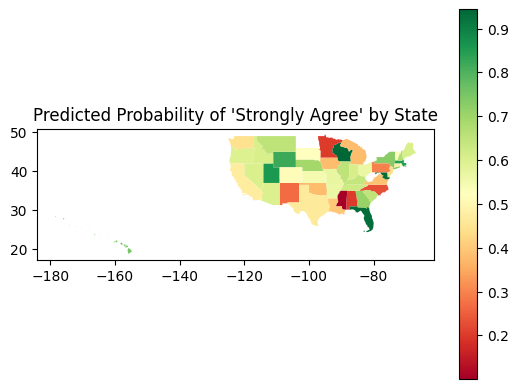

In [ ]:
import pandas as pd
import numpy as np
from cmdstanpy import CmdStanModel
import geopandas as gpd
from libpysal import weights
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/new_abortion_result.csv")

# convert the likert scale variable into ordered categorical variable
likert_order = ["sob1", "sob2", "sob3", "sob4"]
df["y_cat"] = pd.Categorical(df["Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol"],
                             categories=likert_order, ordered=True)
df["y"] = df["y_cat"].cat.codes + 1 #convert to numeric
K = len(likert_order) # number of categories

# Convert predictors to numeric
def encode_var(col):
    le = LabelEncoder()
    return le.fit_transform(df[col]) + 1, len(le.classes_)

df["sex_idx"], J_sex = encode_var("Demo_sex_Symbol")
df["age_idx"], J_age = encode_var("Demo_age_Symbol")
df["eth_idx"], J_eth = encode_var("Demo_ethnicity_Symbol")
df["income_idx"], J_income = encode_var("Demo_household_income_bracket_Symbol")
df["state_idx"], J_state = encode_var("state_cleaned")

# Build adjacency structure for ICAR
shp = gpd.read_file("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp")
shp["STATE"] = shp["STUSPS"].str.upper()

# Match shapefile states to the data states
states_in_data = df["state_cleaned"].str.upper().unique()
shp = shp[shp["STATE"].isin(states_in_data)]

# Create adjacency graph, use existing methods to create edge pairs(https://github.com/ConnorDonegan/Stan-IAR/tree/main), 
# for islands, set everything else to zero and create a seperate random effect
w = weights.Queen.from_dataframe(shp) # Queen contiguity: States are neighbors if they share any boundary point 
edges = []
for i in w.neighbors.keys():  # loop over node IDs
    neighbors = w.neighbors[i]
    if isinstance(neighbors, list) and len(neighbors) == 0:
        # this node has no neighbors (island), do a self loop edge
        edges.append((i+1, i+1))  # self-loop
    else:
        for j in neighbors:
            edges.append((i+1, j+1))  

edges = np.array(edges)
node1, node2 = edges[:,0], edges[:,1]
N_edges = len(node1)  # Count total edges


# Stan data
stan_data = {
    "N": len(df), #number of samples
    "K": K,       #number of y categories
    "y": df["y"].astype(int).tolist(),  #response variables
    "J_sex": J_sex,  #number of sex categories  
    "sex_idx": df["sex_idx"].astype(int).tolist(), # each sample's sex index
    "J_age": J_age,
    "age_idx": df["age_idx"].astype(int).tolist(),
    "J_eth": J_eth,
    "eth_idx": df["eth_idx"].astype(int).tolist(),
    "J_income": J_income,
    "income_idx": df["income_idx"].astype(int).tolist(),
    "J_state": J_state,
    "state_idx": df["state_idx"].astype(int).tolist(),
    "N_edges": N_edges, # total number of neighbour pairs
    "node1": node1.tolist(), # first state in each neighbour pair
    "node2": node2.tolist(), # second state in each neighbour pair
}

# Stan code
stan_code = '''

data {
  int<lower=1> N;                       
  int<lower=2> K;                      
  array[N] int<lower=1, upper=K> y;     

  int<lower=1> J_sex;                   
  int<lower=1> J_age;                    
  int<lower=1> J_eth;                   
  int<lower=1> J_income;                 
  int<lower=1> J_state;                

  array[N] int<lower=1, upper=J_sex> sex_idx;       
  array[N] int<lower=1, upper=J_age> age_idx;       
  array[N] int<lower=1, upper=J_eth> eth_idx;       
  array[N] int<lower=1, upper=J_income> income_idx; 
  array[N] int<lower=1, upper=J_state> state_idx;  

  // ICAR
  int<lower=0> N_edges;                   
  array[N_edges] int<lower=1, upper=J_state> node1; 
  array[N_edges] int<lower=1, upper=J_state> node2;
}


parameters {
  real alpha;                         
  ordered[K - 1] kappa;               

  vector[J_sex] eta_sex;              // sex random effects
  vector[J_age] eta_age;              // age effects (RW1)
  vector[J_eth] eta_eth;              // ethnicity random effects
  vector[J_income] eta_income;        // income effects (RW1)
  vector[J_state] eta_state;          // state spatial effects (ICAR)

  real<lower=0> sigma_sex;
  real<lower=0> sigma_age;
  real<lower=0> sigma_eth;
  real<lower=0> sigma_income;
  real<lower=0> sigma_state;
}

model {
  // Priors
  alpha ~ normal(0, 2);
  kappa ~ normal(0, 3);

  sigma_sex ~ normal(0, 1);
  sigma_age ~ normal(0, 1);
  sigma_eth ~ normal(0, 1);
  sigma_income ~ normal(0, 1);
  sigma_state ~ normal(0, 1);

  // non centered parametrization (seperate mean and variance)
  eta_sex ~ normal(0, sigma_sex); // Independent normal priors
  eta_eth ~ normal(0, sigma_eth);

  // Random walk prior for age
  eta_age[1] ~ normal(0, sigma_age);
  for (j in 2:J_age)
    eta_age[j] ~ normal(eta_age[j - 1], sigma_age);

  // Random walk prior for income
  eta_income[1] ~ normal(0, sigma_income);
  for (j in 2:J_income)
    eta_income[j] ~ normal(eta_income[j - 1], sigma_income);

  // ICAR prior for state
  {
    // penaltize large difference between neighbours
    target += -0.5 * dot_self(eta_state[node1] - eta_state[node2]) / square(sigma_state);
    // sum-to-zero constraint for identifiability
    sum(eta_state) ~ normal(0, 0.001); 
  }

  // Ordered logit:
  for (i in 1:N) {
    real mu = alpha +
              eta_sex[sex_idx[i]] +
              eta_age[age_idx[i]] +
              eta_eth[eth_idx[i]] +
              eta_income[income_idx[i]] +
              eta_state[state_idx[i]];
    y[i] ~ ordered_logistic(mu, kappa);
  }

  // Ordered probit
  /*
  for (i in 1:N) {
    real mu = alpha +
              eta_sex[sex_idx[i]] +
              eta_age[age_idx[i]] +
              eta_eth[eth_idx[i]] +
              eta_income[income_idx[i]] +
              eta_state[state_idx[i]];
    y[i] ~ ordered_probit(mu, kappa);
  }
  */
}

generated quantities {
  vector[N] mu;
  for (i in 1:N)
    mu[i] = alpha +
            eta_sex[sex_idx[i]] +
            eta_age[age_idx[i]] +
            eta_eth[eth_idx[i]] +
            eta_income[income_idx[i]] +
            eta_state[state_idx[i]];
}
'''


# Compile and Sample

with open('mrp.stan', 'w') as f:
    f.write(stan_code)

model = CmdStanModel(stan_file='mrp.stan')

fit = model.sample(
    data=stan_data,
    chains=8,
    parallel_chains=8,
    iter_warmup=2000,
    iter_sampling=1000,
    adapt_delta=0.995,
    max_treedepth=13,
    show_console=True
)

print(fit.summary())


In [11]:

fit.save_csvfiles(dir="output/mrp_results/")

summary_df = fit.summary()

summary_df.to_csv("output/mrp_summary.csv", index=True)

posterior_draws = fit.draws_pd()  

posterior_draws.to_csv("output/mrp_draws.csv", index=False)

In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from cmdstanpy import CmdStanModel
import seaborn as sns


# CREATE STRATIFICATION FRAME

def create_stratification_frame(df, state_order):
    """
    Create a complete stratification frame with all combinations of:
    state × sex × age × ethnicity × income
    
    Parameters
    ----------
    df : pd.DataFrame
        Original data with encoded variables
    state_order : list
        List of state names in encoded order
        
    Returns
    -------
    pd.DataFrame
        Complete stratification frame with indices
    """
    # Get unique categories
    states = sorted(df['state_cleaned'].unique())
    sexes = sorted(df['Demo_sex_Symbol'].unique())
    ages = sorted(df['Demo_age_Symbol'].unique())
    ethnicities = sorted(df['Demo_ethnicity_Symbol'].unique())
    incomes = sorted(df['Demo_household_income_bracket_Symbol'].unique())
    
    # Create all combinations
    from itertools import product
    
    combinations = list(product(states, sexes, ages, ethnicities, incomes))
    
    strat_frame = pd.DataFrame(combinations, 
                               columns=['state', 'sex', 'age', 'ethnicity', 'income'])
    
    # Encode using the same mapping as training data
    from sklearn.preprocessing import LabelEncoder
    
    def encode_with_mapping(df_orig, col_name, strat_df, strat_col):
        le = LabelEncoder()
        le.fit(df_orig[col_name])
        return le.transform(strat_df[strat_col]) + 1
    
    strat_frame['state_idx'] = encode_with_mapping(df, 'state_cleaned', strat_frame, 'state')
    strat_frame['sex_idx'] = encode_with_mapping(df, 'Demo_sex_Symbol', strat_frame, 'sex')
    strat_frame['age_idx'] = encode_with_mapping(df, 'Demo_age_Symbol', strat_frame, 'age')
    strat_frame['eth_idx'] = encode_with_mapping(df, 'Demo_ethnicity_Symbol', strat_frame, 'ethnicity')
    strat_frame['income_idx'] = encode_with_mapping(df, 'Demo_household_income_bracket_Symbol', strat_frame, 'income')
    
    print(f"Stratification frame created: {len(strat_frame):,} cells")
    print(f"  States: {len(states)}")
    print(f"  Sex: {len(sexes)}")
    print(f"  Age: {len(ages)}")
    print(f"  Ethnicity: {len(ethnicities)}")
    print(f"  Income: {len(incomes)}")
    
    return strat_frame


# ============================================================
# STEP 3: ADD POPULATION WEIGHTS
# ============================================================

def add_population_weights(strat_frame, acs_data_path=None):
    """
    Add population weights to stratification frame.
    
    If ACS data is not available, uses uniform weights within states
    based on observed sample proportions.
    
    Parameters
    ----------
    strat_frame : pd.DataFrame
        Stratification frame
    acs_data_path : str, optional
        Path to ACS population data (if available)
        
    Returns
    -------
    pd.DataFrame
        Stratification frame with 'population' column
    """
    if acs_data_path is not None:
        # Load actual ACS population data
        acs = pd.read_csv(acs_data_path)
        strat_frame = strat_frame.merge(acs, 
                                        on=['state', 'sex', 'age', 'ethnicity', 'income'],
                                        how='left')
        strat_frame['population'] = strat_frame['population'].fillna(0)
    else:
        # Use sample-based weights (rough approximation)
        print("Warning: Using sample-based weights. For accurate MrP, provide ACS data.")
        
        # Count observations in each cell
        cell_counts = df.groupby(['state_cleaned', 'Demo_sex_Symbol', 
                                  'Demo_age_Symbol', 'Demo_ethnicity_Symbol',
                                  'Demo_household_income_bracket_Symbol']).size().reset_index(name='count')
        
        cell_counts.columns = ['state', 'sex', 'age', 'ethnicity', 'income', 'count']
        
        strat_frame = strat_frame.merge(cell_counts, 
                                        on=['state', 'sex', 'age', 'ethnicity', 'income'],
                                        how='left')
        strat_frame['count'] = strat_frame['count'].fillna(0)
        
        # Convert counts to proportions within states
        state_totals = strat_frame.groupby('state')['count'].transform('sum')
        strat_frame['population'] = strat_frame['count'] / state_totals
        strat_frame['population'] = strat_frame['population'].fillna(1.0 / len(strat_frame))
    
    # Normalize within states
    state_sums = strat_frame.groupby('state')['population'].transform('sum')
    strat_frame['population'] = strat_frame['population'] / state_sums
    
    print(f"Population weights added. Sum per state: {strat_frame.groupby('state')['population'].sum().mean():.3f}")
    
    return strat_frame


# ============================================================
# STEP 4: GENERATE PREDICTIONS
# ============================================================

def generate_predictions(fit, strat_frame, stan_data):
    """
    Generate predictions for all cells in stratification frame.
    
    Parameters
    ----------
    fit : CmdStanMCMC
        Fitted Stan model
    strat_frame : pd.DataFrame
        Stratification frame with indices
    stan_data : dict
        Original Stan data (for alpha and kappa)
        
    Returns
    -------
    pd.DataFrame
        Stratification frame with predictions
    """
    # Extract posterior samples
    alpha = fit.stan_variable('alpha')
    kappa = fit.stan_variable('kappa')
    eta_sex = fit.stan_variable('eta_sex')
    eta_age = fit.stan_variable('eta_age')
    eta_eth = fit.stan_variable('eta_eth')
    eta_income = fit.stan_variable('eta_income')
    eta_state = fit.stan_variable('eta_state')
    
    n_draws = alpha.shape[0]
    n_cells = len(strat_frame)
    
    print(f"Generating predictions for {n_cells:,} cells × {n_draws:,} draws...")
    
    # Calculate linear predictor for each cell and draw
    mu_draws = np.zeros((n_cells, n_draws))
    
    for i, row in strat_frame.iterrows():
        if i % 10000 == 0:
            print(f"  Processing cell {i:,} / {n_cells:,}")
        
        mu_draws[i, :] = (
            alpha +
            eta_sex[:, row['sex_idx'] - 1] +
            eta_age[:, row['age_idx'] - 1] +
            eta_eth[:, row['eth_idx'] - 1] +
            eta_income[:, row['income_idx'] - 1] +
            eta_state[:, row['state_idx'] - 1]
        )
    
    # Convert to probabilities for each Likert category
    K = stan_data['K']
    prob_draws = np.zeros((n_cells, n_draws, K))
    
    for k in range(K):
        if k == 0:
            # P(Y = 1) = logistic(kappa[1] - mu)
            prob_draws[:, :, k] = 1 / (1 + np.exp(-(kappa[:, 0] - mu_draws)))
        elif k == K - 1:
            # P(Y = K) = 1 - logistic(kappa[K-1] - mu)
            prob_draws[:, :, k] = 1 - (1 / (1 + np.exp(-(kappa[:, K-2] - mu_draws))))
        else:
            # P(Y = k) = logistic(kappa[k] - mu) - logistic(kappa[k-1] - mu)
            upper = 1 / (1 + np.exp(-(kappa[:, k] - mu_draws)))
            lower = 1 / (1 + np.exp(-(kappa[:, k-1] - mu_draws)))
            prob_draws[:, :, k] = upper - lower
    
    # Calculate expected value: E[Y] = sum(k * P(Y=k))
    categories = np.arange(1, K + 1)
    expected_y = np.sum(prob_draws * categories[np.newaxis, np.newaxis, :], axis=2)
    
    # Store mean and quantiles
    strat_frame['pred_mean'] = expected_y.mean(axis=1)
    strat_frame['pred_median'] = np.median(expected_y, axis=1)
    strat_frame['pred_lower'] = np.percentile(expected_y, 2.5, axis=1)
    strat_frame['pred_upper'] = np.percentile(expected_y, 97.5, axis=1)
    strat_frame['pred_sd'] = expected_y.std(axis=1)
    
    # Also store probability of each category
    for k in range(K):
        strat_frame[f'prob_cat_{k+1}'] = prob_draws[:, :, k].mean(axis=1)
    
    print("✓ Predictions generated")
    
    return strat_frame


# ============================================================
# STEP 5: POST-STRATIFY TO STATE LEVEL
# ============================================================

def poststratify_state_level(strat_frame):
    """
    Aggregate cell-level predictions to state level using population weights.
    
    Parameters
    ----------
    strat_frame : pd.DataFrame
        Stratification frame with predictions and weights
        
    Returns
    -------
    pd.DataFrame
        State-level aggregated predictions
    """
    state_preds = strat_frame.groupby('state').apply(
        lambda x: pd.Series({
            'pred_mean': np.average(x['pred_mean'], weights=x['population']),
            'pred_median': np.average(x['pred_median'], weights=x['population']),
            'pred_lower': np.average(x['pred_lower'], weights=x['population']),
            'pred_upper': np.average(x['pred_upper'], weights=x['population']),
            'pred_sd': np.sqrt(np.average(x['pred_sd']**2, weights=x['population'])),
            'n_cells': len(x),
            'total_pop': x['population'].sum()
        })
    ).reset_index()
    
    print(f"\n✓ State-level predictions aggregated for {len(state_preds)} states")
    print(f"  Mean prediction range: [{state_preds['pred_mean'].min():.2f}, {state_preds['pred_mean'].max():.2f}]")
    
    return state_preds


# ============================================================
# STEP 6: MAP VISUALIZATION
# ============================================================

def map_state_predictions(state_preds, shp_path, output_path='mrp_map.png', 
                          variable='pred_mean', title='MrP State-Level Predictions'):
    """
    Create a choropleth map of state-level predictions.
    
    Parameters
    ----------
    state_preds : pd.DataFrame
        State-level predictions
    shp_path : str
        Path to US states shapefile
    output_path : str
        Where to save the map
    variable : str
        Which variable to map ('pred_mean', 'pred_median', etc.)
    title : str
        Map title
    """
    # Load shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    
    # Merge predictions
    state_preds['STATE'] = state_preds['state'].str.upper()
    shp = shp.merge(state_preds[['STATE', variable, 'pred_lower', 'pred_upper']], 
                    on='STATE', how='left')
    
    # Filter to contiguous US + Alaska + Hawaii
    shp = shp[~shp['STATE'].isin(['PR', 'VI', 'GU', 'AS', 'MP'])]
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(16, 10))
    
    # Plot
    shp.plot(column=variable, 
             ax=ax,
             legend=True,
             cmap='RdYlGn',  # Red (low) to Yellow to Green (high)
             edgecolor='black',
             linewidth=0.5,
             legend_kwds={'label': 'Expected Likert Response (1-4)',
                         'orientation': 'horizontal',
                         'shrink': 0.6,
                         'pad': 0.05})
    
    # Styling
    ax.set_title(title, fontsize=18, fontweight='bold', pad=20)
    ax.axis('off')
    
    # Add Alaska and Hawaii as insets (optional, simplified version)
    # For production, you'd want proper Alaska/Hawaii repositioning
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"\n✓ Map saved to {output_path}")
    plt.show()
    
    return fig, ax


def create_uncertainty_map(state_preds, shp_path, output_path='mrp_uncertainty_map.png'):
    """
    Create a map showing prediction uncertainty (credible interval width).
    """
    state_preds['ci_width'] = state_preds['pred_upper'] - state_preds['pred_lower']
    
    fig, ax = map_state_predictions(state_preds, shp_path, 
                                     output_path=output_path,
                                     variable='ci_width',
                                     title='Prediction Uncertainty (95% CI Width)')
    return fig, ax


# ============================================================
# STEP 7: SUMMARY VISUALIZATIONS
# ============================================================

def plot_state_rankings(state_preds, top_n=10, output_path='state_rankings.png'):
    """
    Plot top and bottom states by predicted support.
    """
    sorted_states = state_preds.sort_values('pred_mean', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Top states
    top = sorted_states.head(top_n)
    axes[0].barh(range(len(top)), top['pred_mean'], color='green', alpha=0.7)
    axes[0].set_yticks(range(len(top)))
    axes[0].set_yticklabels(top['state'])
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Predicted Support (1-4 scale)')
    axes[0].set_title(f'Top {top_n} States (Highest Support)')
    axes[0].axvline(state_preds['pred_mean'].mean(), color='red', linestyle='--', 
                    label='National avg')
    axes[0].legend()
    
    # Bottom states
    bottom = sorted_states.tail(top_n)
    axes[1].barh(range(len(bottom)), bottom['pred_mean'], color='red', alpha=0.7)
    axes[1].set_yticks(range(len(bottom)))
    axes[1].set_yticklabels(bottom['state'])
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Predicted Support (1-4 scale)')
    axes[1].set_title(f'Bottom {top_n} States (Lowest Support)')
    axes[1].axvline(state_preds['pred_mean'].mean(), color='red', linestyle='--',
                   label='National avg')
    axes[1].legend()
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"✓ Rankings plot saved to {output_path}")
    plt.show()


# ============================================================
# FULL WORKFLOW EXAMPLE
# ============================================================

if __name__ == "__main__":
    # Assuming you have these from your data prep:
    # - df: original data
    # - fit: fitted Stan model
    # - stan_data: Stan input data
    # - state_order: list of states in encoded order
    # - shp_path: path to shapefile
    
    print("="*60)
    print("MrP POST-STRATIFICATION AND MAPPING")
    print("="*60)
    
    # Step 1: Create stratification frame
    strat_frame = create_stratification_frame(df, state_order)
    
    # Step 2: Add population weights
    strat_frame = add_population_weights(strat_frame, acs_data_path=None)
    
    # Step 3: Generate predictions
    strat_frame = generate_predictions(fit, strat_frame, stan_data)
    
    # Step 4: Aggregate to state level
    state_preds = poststratify_state_level(strat_frame)
    
    # Step 5: Create maps
    shp_path = "/mnt/c/Users/yuyue/Dropbox/.../tl_2025_us_state.shp"
    map_state_predictions(state_preds, shp_path, 
                         output_path='abortion_mrp_map.png',
                         title='State-Level Abortion Support (MrP Estimates)')
    
    create_uncertainty_map(state_preds, shp_path,
                          output_path='abortion_uncertainty_map.png')
    
    # Step 6: Rankings
    plot_state_rankings(state_preds, top_n=10)
    
    # Step 7: Save results
    state_preds.to_csv('state_level_predictions.csv', index=False)
    strat_frame.to_csv('cell_level_predictions.csv', index=False)
    
    print("\n" + "="*60)
    print("✓ MrP ANALYSIS COMPLETE")
    print("="*60)
    print(f"State predictions: state_level_predictions.csv")
    print(f"Cell predictions: cell_level_predictions.csv")
    print(f"Maps: abortion_mrp_map.png, abortion_uncertainty_map.png")

In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from cmdstanpy import CmdStanModel
import seaborn as sns


# CREATE STRATIFICATION FRAME

def create_stratification_frame(df, state_order):

    # Get unique categories
    states = sorted(df['state_cleaned'].unique())
    sexes = sorted(df['Demo_sex_Symbol'].unique())
    ages = sorted(df['Demo_age_Symbol'].unique())
    ethnicities = sorted(df['Demo_ethnicity_Symbol'].unique())
    incomes = sorted(df['Demo_household_income_bracket_Symbol'].unique())
    
    # Create all combinations
    from itertools import product
    
    combinations = list(product(states, sexes, ages, ethnicities, incomes))
    
    strat_frame = pd.DataFrame(combinations, 
                               columns=['state', 'sex', 'age', 'ethnicity', 'income'])
    
    # Encode using the same mapping as training data
    from sklearn.preprocessing import LabelEncoder
    
    def encode_with_mapping(df_orig, col_name, strat_df, strat_col):
        le = LabelEncoder()
        le.fit(df_orig[col_name])
        return le.transform(strat_df[strat_col]) + 1
    
    strat_frame['state_idx'] = encode_with_mapping(df, 'state_cleaned', strat_frame, 'state')
    strat_frame['sex_idx'] = encode_with_mapping(df, 'Demo_sex_Symbol', strat_frame, 'sex')
    strat_frame['age_idx'] = encode_with_mapping(df, 'Demo_age_Symbol', strat_frame, 'age')
    strat_frame['eth_idx'] = encode_with_mapping(df, 'Demo_ethnicity_Symbol', strat_frame, 'ethnicity')
    strat_frame['income_idx'] = encode_with_mapping(df, 'Demo_household_income_bracket_Symbol', strat_frame, 'income')
    
    print(f"Stratification frame created: {len(strat_frame):,} cells")
    print(f"  States: {len(states)}")
    print(f"  Sex: {len(sexes)}")
    print(f"  Age: {len(ages)}")
    print(f"  Ethnicity: {len(ethnicities)}")
    print(f"  Income: {len(incomes)}")
    
    return strat_frame


# add population weights

def add_population_weights(strat_frame):

    strat_frame = strat_frame.merge(df, 
                                        on=['state', 'sex', 'age', 'ethnicity', 'income'],
                                        how='left')
    strat_frame['population'] = strat_frame['population'].fillna(0)
    
    # Normalize within states
    state_sums = strat_frame.groupby('state')['population'].transform('sum')
    strat_frame['population'] = strat_frame['population'] / state_sums
    
    print(f"Population weights added. Sum per state: {strat_frame.groupby('state')['population'].sum().mean():.3f}")
    
    return strat_frame


# GENERATE PREDICTIONS

def generate_predictions(fit, strat_frame, stan_data):
    """
    Generate predictions for all cells in stratification frame.
    
    Parameters
    ----------
    fit : CmdStanMCMC
        Fitted Stan model
    strat_frame : pd.DataFrame
        Stratification frame with indices
    stan_data : dict
        Original Stan data (for alpha and kappa)
        
    Returns
    -------
    pd.DataFrame
        Stratification frame with predictions
    """
    # Extract posterior samples
    alpha = fit.stan_variable('alpha')
    kappa = fit.stan_variable('kappa')
    eta_sex = fit.stan_variable('eta_sex')
    eta_age = fit.stan_variable('eta_age')
    eta_eth = fit.stan_variable('eta_eth')
    eta_income = fit.stan_variable('eta_income')
    eta_state = fit.stan_variable('eta_state')
    
    n_draws = alpha.shape[0]
    n_cells = len(strat_frame)
    
    print(f"Generating predictions for {n_cells:,} cells × {n_draws:,} draws...")
    
    # Calculate linear predictor for each cell and draw
    mu_draws = np.zeros((n_cells, n_draws))
    
    for i, row in strat_frame.iterrows():
        if i % 10000 == 0:
            print(f"  Processing cell {i:,} / {n_cells:,}")
        
        mu_draws[i, :] = (
            alpha +
            eta_sex[:, row['sex_idx'] - 1] +
            eta_age[:, row['age_idx'] - 1] +
            eta_eth[:, row['eth_idx'] - 1] +
            eta_income[:, row['income_idx'] - 1] +
            eta_state[:, row['state_idx'] - 1]
        )
    
    # Convert to probabilities for each Likert category
    K = stan_data['K']
    prob_draws = np.zeros((n_cells, n_draws, K))
    
    for k in range(K):
        if k == 0:
            # P(Y = 1) = logistic(kappa[1] - mu)
            prob_draws[:, :, k] = 1 / (1 + np.exp(-(kappa[:, 0] - mu_draws)))
        elif k == K - 1:
            # P(Y = K) = 1 - logistic(kappa[K-1] - mu)
            prob_draws[:, :, k] = 1 - (1 / (1 + np.exp(-(kappa[:, K-2] - mu_draws))))
        else:
            # P(Y = k) = logistic(kappa[k] - mu) - logistic(kappa[k-1] - mu)
            upper = 1 / (1 + np.exp(-(kappa[:, k] - mu_draws)))
            lower = 1 / (1 + np.exp(-(kappa[:, k-1] - mu_draws)))
            prob_draws[:, :, k] = upper - lower
    
    # Calculate expected value: E[Y] = sum(k * P(Y=k))
    categories = np.arange(1, K + 1)
    expected_y = np.sum(prob_draws * categories[np.newaxis, np.newaxis, :], axis=2)
    
    # Store mean and quantiles
    strat_frame['pred_mean'] = expected_y.mean(axis=1)
    strat_frame['pred_median'] = np.median(expected_y, axis=1)
    strat_frame['pred_lower'] = np.percentile(expected_y, 2.5, axis=1)
    strat_frame['pred_upper'] = np.percentile(expected_y, 97.5, axis=1)
    strat_frame['pred_sd'] = expected_y.std(axis=1)
    
    # Also store probability of each category
    for k in range(K):
        strat_frame[f'prob_cat_{k+1}'] = prob_draws[:, :, k].mean(axis=1)
    
    print("✓ Predictions generated")
    
    return strat_frame


# POST-STRATIFY TO STATE LEVEL
def poststratify_state_level(strat_frame):
    """
    Aggregate cell-level predictions to state level using population weights.
    
    Parameters
    ----------
    strat_frame : pd.DataFrame
        Stratification frame with predictions and weights
        
    Returns
    -------
    pd.DataFrame
        State-level aggregated predictions
    """
    state_preds = strat_frame.groupby('state').apply(
        lambda x: pd.Series({
            'pred_mean': np.average(x['pred_mean'], weights=x['population']),
            'pred_median': np.average(x['pred_median'], weights=x['population']),
            'pred_lower': np.average(x['pred_lower'], weights=x['population']),
            'pred_upper': np.average(x['pred_upper'], weights=x['population']),
            'pred_sd': np.sqrt(np.average(x['pred_sd']**2, weights=x['population'])),
            'n_cells': len(x),
            'total_pop': x['population'].sum()
        })
    ).reset_index()
    
    print(f"\n✓ State-level predictions aggregated for {len(state_preds)} states")
    print(f"  Mean prediction range: [{state_preds['pred_mean'].min():.2f}, {state_preds['pred_mean'].max():.2f}]")
    
    return state_preds


#  MAP VISUALIZATION

def map_state_predictions(state_preds, shp_path, output_path='mrp_map.png', 
                          variable='pred_mean', title='MrP State-Level Predictions'):
    """
    Create a choropleth map of state-level predictions.
    
    Parameters
    ----------
    state_preds : pd.DataFrame
        State-level predictions
    shp_path : str
        Path to US states shapefile
    output_path : str
        Where to save the map
    variable : str
        Which variable to map ('pred_mean', 'pred_median', etc.)
    title : str
        Map title
    """
    # Load shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    
    # Merge predictions
    state_preds['STATE'] = state_preds['state'].str.upper()
    shp = shp.merge(state_preds[['STATE', variable, 'pred_lower', 'pred_upper']], 
                    on='STATE', how='left')
    
    # Filter to contiguous US + Alaska + Hawaii
    shp = shp[~shp['STATE'].isin(['PR', 'VI', 'GU', 'AS', 'MP'])]
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(16, 10))
    
    # Plot
    shp.plot(column=variable, 
             ax=ax,
             legend=True,
             cmap='RdYlGn',  # Red (low) to Yellow to Green (high)
             edgecolor='black',
             linewidth=0.5,
             legend_kwds={'label': 'Expected Likert Response (1-4)',
                         'orientation': 'horizontal',
                         'shrink': 0.6,
                         'pad': 0.05})
    
    # Styling
    ax.set_title(title, fontsize=18, fontweight='bold', pad=20)
    ax.axis('off')
    
    # Add Alaska and Hawaii as insets (optional, simplified version)
    # For production, you'd want proper Alaska/Hawaii repositioning
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"\n✓ Map saved to {output_path}")
    plt.show()
    
    return fig, ax


def create_uncertainty_map(state_preds, shp_path, output_path='mrp_uncertainty_map.png'):
    """
    Create a map showing prediction uncertainty (credible interval width).
    """
    state_preds['ci_width'] = state_preds['pred_upper'] - state_preds['pred_lower']
    
    fig, ax = map_state_predictions(state_preds, shp_path, 
                                     output_path=output_path,
                                     variable='ci_width',
                                     title='Prediction Uncertainty (95% CI Width)')
    return fig, ax


# SUMMARY VISUALIZATIONS

def plot_state_rankings(state_preds, top_n=10, output_path='state_rankings.png'):
    """
    Plot top and bottom states by predicted support.
    """
    sorted_states = state_preds.sort_values('pred_mean', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Top states
    top = sorted_states.head(top_n)
    axes[0].barh(range(len(top)), top['pred_mean'], color='green', alpha=0.7)
    axes[0].set_yticks(range(len(top)))
    axes[0].set_yticklabels(top['state'])
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Predicted Support (1-4 scale)')
    axes[0].set_title(f'Top {top_n} States (Highest Support)')
    axes[0].axvline(state_preds['pred_mean'].mean(), color='red', linestyle='--', 
                    label='National avg')
    axes[0].legend()
    
    # Bottom states
    bottom = sorted_states.tail(top_n)
    axes[1].barh(range(len(bottom)), bottom['pred_mean'], color='red', alpha=0.7)
    axes[1].set_yticks(range(len(bottom)))
    axes[1].set_yticklabels(bottom['state'])
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Predicted Support (1-4 scale)')
    axes[1].set_title(f'Bottom {top_n} States (Lowest Support)')
    axes[1].axvline(state_preds['pred_mean'].mean(), color='red', linestyle='--',
                   label='National avg')
    axes[1].legend()
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"✓ Rankings plot saved to {output_path}")
    plt.show()

if __name__ == "__main__":

    strat_frame = create_stratification_frame(df, state_order)
    
    strat_frame = add_population_weights(strat_frame, acs_data_path=None)
    
    strat_frame = generate_predictions(fit, strat_frame, stan_data)
    
    state_preds = poststratify_state_level(strat_frame)
    
    shp_path = "/mnt/c/Users/yuyue/Dropbox/.../tl_2025_us_state.shp"
    map_state_predictions(state_preds, shp_path, 
                         output_path='abortion_mrp_map.png',
                         title='State-Level Abortion Support (MrP Estimates)')
    
    create_uncertainty_map(state_preds, shp_path,
                          output_path='abortion_uncertainty_map.png')
    
    plot_state_rankings(state_preds, top_n=10)
    
    state_preds.to_csv('state_level_predictions.csv', index=False)
    strat_frame.to_csv('cell_level_predictions.csv', index=False)
    
    print("\n" + "="*60)
    print("✓ MrP ANALYSIS COMPLETE")
    print("="*60)
    print(f"State predictions: state_level_predictions.csv")
    print(f"Cell predictions: cell_level_predictions.csv")
    print(f"Maps: abortion_mrp_map.png, abortion_uncertainty_map.png")